# TA-03: Prediksi Pembelian Asuransi Perjalanan dengan Regresi Logistik
Studi kasus: tim pemasaran ingin tahu pelanggan mana yang kemungkinan membeli asuransi perjalanan.
Dataset: *Travel Insurance Prediction Data* (Kaggle, tejashvi14). Target: `TravelInsurance` (1 = beli, 0 = tidak).

## 1. Import library dan muat data

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, roc_auc_score, ConfusionMatrixDisplay)
sns.set_theme(style="whitegrid")
df = pd.read_csv("data/TravelInsurancePrediction.csv").drop(columns=["Unnamed: 0"])
df.head()

,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,Yes,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


## 2. Eksplorasi data (EDA)

In [2]:
print(df.shape)
print("Missing value:", df.isna().sum().sum(), "| Duplikat:", df.duplicated().sum())
df.describe().T

(1987, 9)
Missing value: 0 | Duplikat: 738


,count,mean,std,min,25%,50%,75%,max
Age,1987.0,29.650226,2.913308,25.0,28.0,29.0,32.0,35.0
AnnualIncome,1987.0,932762.959235,376855.684748,300000.0,600000.0,900000.0,1250000.0,1800000.0
FamilyMembers,1987.0,4.752894,1.609650,2.0,4.0,5.0,6.0,9.0
ChronicDiseases,1987.0,0.277806,0.448030,0.0,0.0,0.0,1.0,1.0
TravelInsurance,1987.0,0.357323,0.479332,0.0,0.0,0.0,1.0,1.0


### Distribusi target dan pemeriksaan ketidakseimbangan kelas

TravelInsurance
0    1277
1     710
Name: count, dtype: int64
TravelInsurance
0    64.3
1    35.7
Name: proportion, dtype: float64


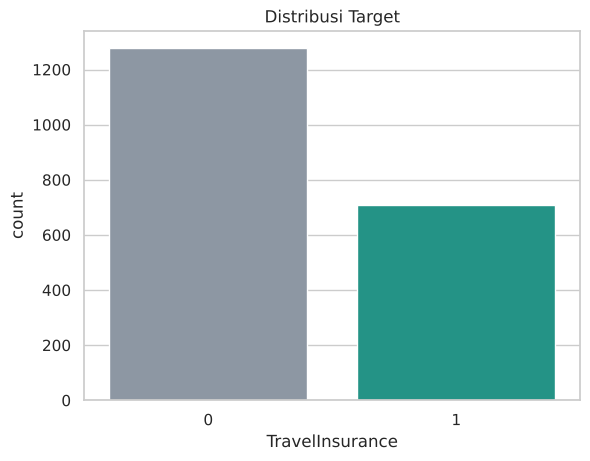

In [3]:
print(df["TravelInsurance"].value_counts())
print((df["TravelInsurance"].value_counts(normalize=True)*100).round(1))
sns.countplot(x="TravelInsurance", data=df, hue="TravelInsurance", palette=["#8a97a6","#12a594"], legend=False)
plt.title("Distribusi Target"); plt.show()

Kelas "Beli" sekitar 36%. Ini masih tergolong cukup seimbang (bukan kasus ekstrem seperti 5%), jadi **SMOTE tidak diperlukan**. Sebagai gantinya dipakai `class_weight='balanced'` yang lebih sederhana.

### Hubungan fitur dengan target

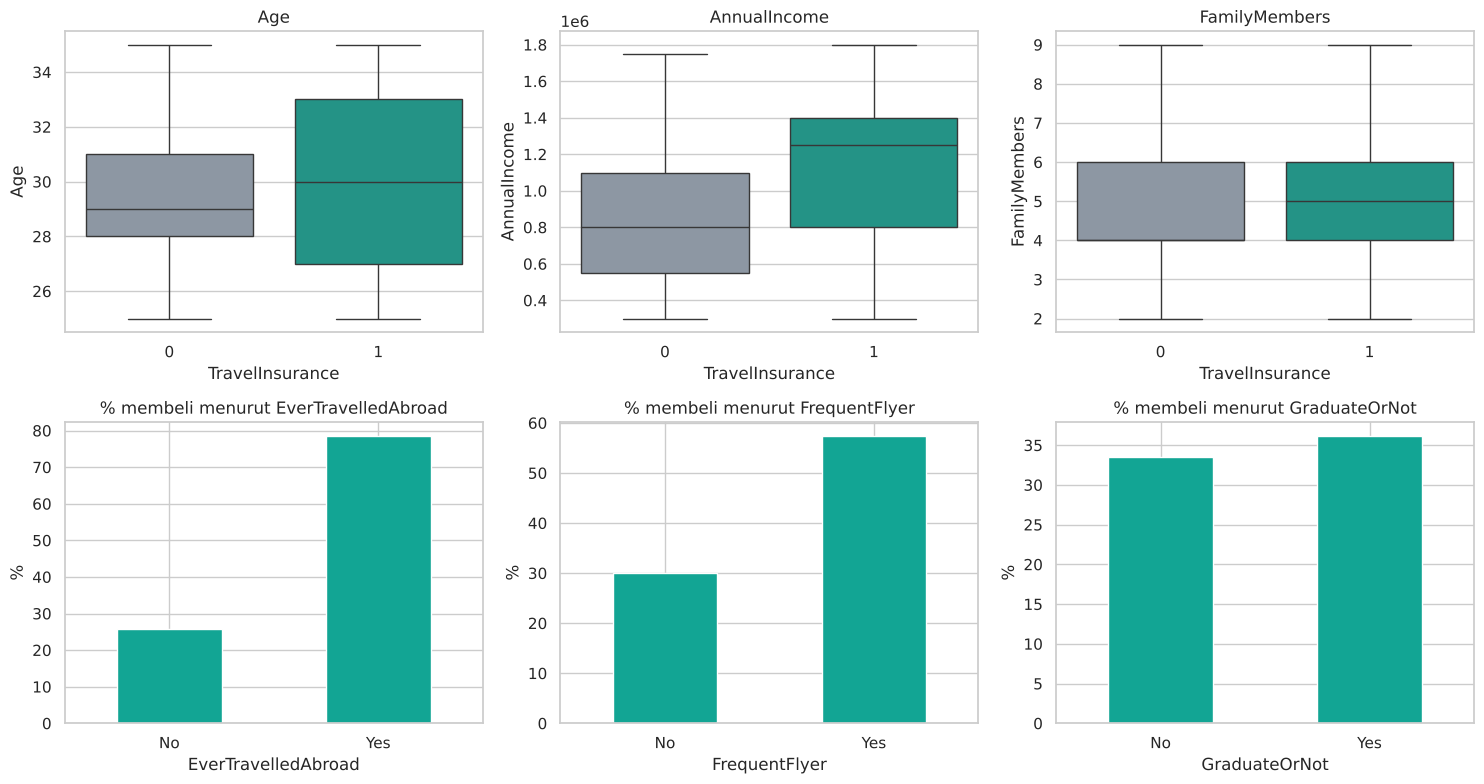

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.flat[:3], ["Age", "AnnualIncome", "FamilyMembers"]):
    sns.boxplot(x="TravelInsurance", y=c, data=df, ax=a, hue="TravelInsurance", palette=["#8a97a6","#12a594"], legend=False); a.set_title(c)
for a, c in zip(ax.flat[3:], ["EverTravelledAbroad", "FrequentFlyer", "GraduateOrNot"]):
    (df.groupby(c)["TravelInsurance"].mean()*100).plot.bar(ax=a, color="#12a594"); a.set_title(f"% membeli menurut {c}"); a.set_ylabel("%"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

Pelanggan yang **pernah ke luar negeri**, **sering terbang**, dan **berpendapatan tinggi** lebih sering membeli asuransi.

## 3. Pra-pemrosesan data

In [5]:
d = df.copy()
d["Employment Type"] = (d["Employment Type"] == "Private Sector/Self Employed").astype(int)
for c in ["GraduateOrNot", "FrequentFlyer", "EverTravelledAbroad"]:
    d[c] = (d[c] == "Yes").astype(int)
d = d.rename(columns={"Employment Type": "PrivateSector"})
FITUR = ["Age","AnnualIncome","FamilyMembers","ChronicDiseases","PrivateSector","GraduateOrNot","FrequentFlyer","EverTravelledAbroad"]
NUMERIK = ["Age","AnnualIncome","FamilyMembers"]
X, y = d[FITUR], d["TravelInsurance"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_tr[NUMERIK])
X_tr_s, X_te_s = X_tr.copy(), X_te.copy()
X_tr_s[NUMERIK] = scaler.transform(X_tr[NUMERIK]); X_te_s[NUMERIK] = scaler.transform(X_te[NUMERIK])
print(X_tr.shape, X_te.shape)

(1589, 8) (398, 8)


Data tidak punya missing value. Variabel kategorikal diubah jadi 0/1, lalu fitur numerik distandarisasi (scaler hanya di-*fit* pada data latih agar tidak ada kebocoran data).

## 4. Pelatihan model

In [6]:
m_default  = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s, y_tr)
m_balanced = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42).fit(X_tr_s, y_tr)
for nama, m in [("default", m_default), ("balanced", m_balanced)]:
    print(nama); print(classification_report(y_te, m.predict(X_te_s), target_names=["Tidak Beli","Beli"]))

default
              precision    recall  f1-score   support

  Tidak Beli       0.77      0.91      0.83       256
        Beli       0.75      0.51      0.61       142

    accuracy                           0.76       398
   macro avg       0.76      0.71      0.72       398
weighted avg       0.76      0.76      0.75       398

balanced
              precision    recall  f1-score   support

  Tidak Beli       0.78      0.77      0.77       256
        Beli       0.59      0.62      0.61       142

    accuracy                           0.71       398
   macro avg       0.69      0.69      0.69       398
weighted avg       0.72      0.71      0.71       398



Dengan `class_weight='balanced'`, **Recall kelas Beli naik** (dari sekitar 0,51 menjadi 0,62) dan F1 hampir sama, jadi model ini dipilih.

In [7]:
model = m_balanced

## 5. Evaluasi model

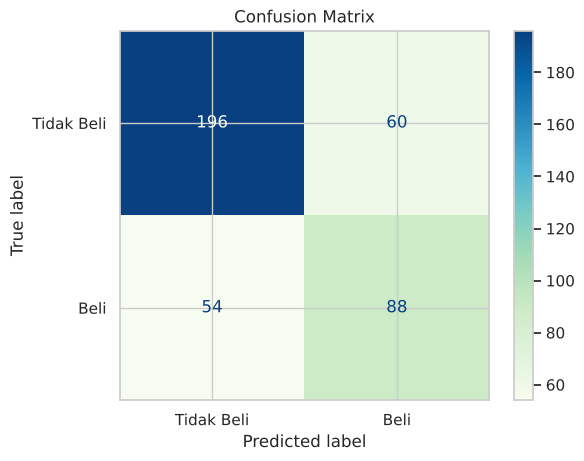

TN=196 FP=60 FN=54 TP=88


In [8]:
pred = model.predict(X_te_s); proba = model.predict_proba(X_te_s)[:, 1]
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Tidak Beli","Beli"]).plot(cmap="GnBu")
plt.title("Confusion Matrix"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

- **False Positive**: diprediksi beli padahal tidak. Kerugiannya kecil (biaya promosi terbuang).
- **False Negative**: diprediksi tidak beli padahal mau beli. Peluang penjualan hilang, jadi lebih merugikan.
- Karena itu **Recall** kelas "Beli" dijadikan metrik utama.

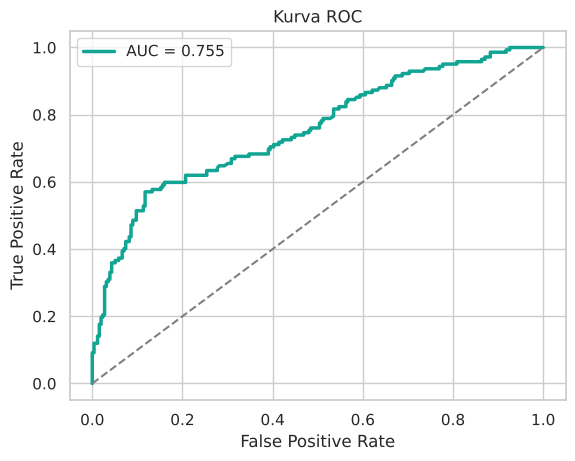

AUC 5-fold CV: [0.734 0.792 0.786 0.739 0.773] rata-rata 0.765


In [9]:
auc = roc_auc_score(y_te, proba)
fpr, tpr, _ = roc_curve(y_te, proba)
plt.plot(fpr, tpr, color="#12a594", lw=2.5, label=f"AUC = {auc:.3f}"); plt.plot([0,1],[0,1],"--",color="grey")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Kurva ROC"); plt.legend(); plt.show()
X_all = X.copy(); X_all[NUMERIK] = StandardScaler().fit_transform(X[NUMERIK])
cv = cross_val_score(LogisticRegression(max_iter=1000, class_weight="balanced"), X_all, y, cv=5, scoring="roc_auc")
print("AUC 5-fold CV:", cv.round(3), "rata-rata", cv.mean().round(3))

AUC sekitar 0,75 berarti model cukup mampu membedakan pembeli dan bukan pembeli, tapi belum sempurna. Hasil CV (sekitar 0,77) konsisten dengan hasil di data uji, jadi tidak ada tanda overfitting.

### Pengaruh fitur

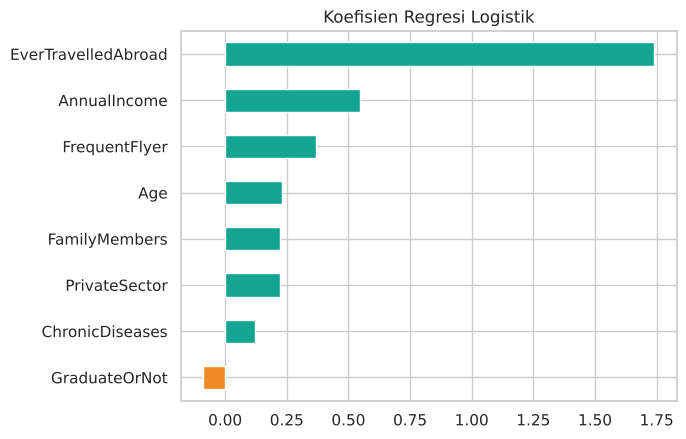

In [10]:
koef = pd.Series(model.coef_[0], index=FITUR).sort_values()
koef.plot.barh(color=["#f08a24" if v<0 else "#12a594" for v in koef]); plt.title("Koefisien Regresi Logistik"); plt.show()

Fitur paling berpengaruh: **pernah ke luar negeri**, lalu **pendapatan tahunan** dan **sering terbang**.

## 6. Simpan model dan scaler dengan Joblib
Model final yang dipakai aplikasi dilatih lewat `train_model.py` (logika sama dengan notebook ini).

In [11]:
joblib.dump(model, "model/model_notebook.joblib"); joblib.dump(scaler, "model/scaler_notebook.joblib")
print("Tersimpan.")

Tersimpan.


## 7. Kesimpulan
1. Regresi Logistik dengan `class_weight='balanced'` mencapai akurasi sekitar 71%, Recall 62%, dan AUC 0,755.
2. Kelas target cukup seimbang, jadi SMOTE tidak diperlukan.
3. Pelanggan yang pernah ke luar negeri, sering terbang, dan berpendapatan tinggi paling berpeluang membeli. Tim pemasaran bisa memprioritaskan kelompok ini.
4. Keterbatasan: dataset kecil (1.987 data) dan hanya 8 fitur, sehingga hasilnya adalah perkiraan, bukan kepastian.